In [9]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [10]:
X, y = load_diabetes(return_X_y= True, as_frame= True)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= 42)
print(len(X_train), len(y_train))

353 353


In [12]:
model = XGBRegressor(eval_metric= 'rmse', random_state= 42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [13]:
print("mean squared error : ", mean_squared_error(y_test, y_pred))
print("r2 score : ", r2_score(y_test, y_pred))

mean squared error :  3351.001637862091
r2 score :  0.3675149756138415


In [14]:
import pandas as pd
importances = model.feature_importances_

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances 
    
}).sort_values(by='Importance', ascending= True)


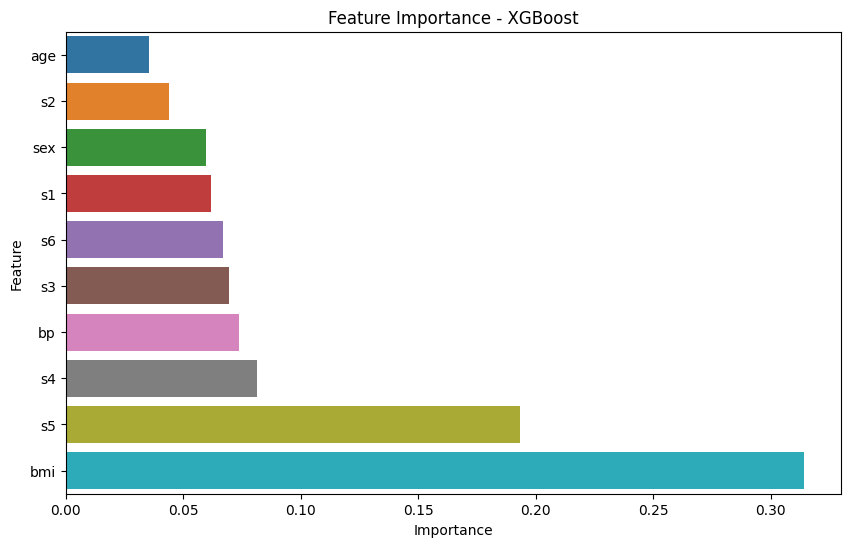

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(x= 'Importance', y='Feature', data=feat_imp)
plt.title('Feature Importance - XGBoost')
plt.show()